PARTE 1.1 - Resultados
      p  sesgo_media  ecm_media  sesgo_mediana  ecm_mediana
0  0.00     0.004570   0.010617       0.006545     0.015216
1  0.05     0.253578   0.074621       0.071316     0.021407
2  0.10     0.504456   0.265451       0.144605     0.038793
3  0.20     1.002559   1.015301       0.320843     0.123657


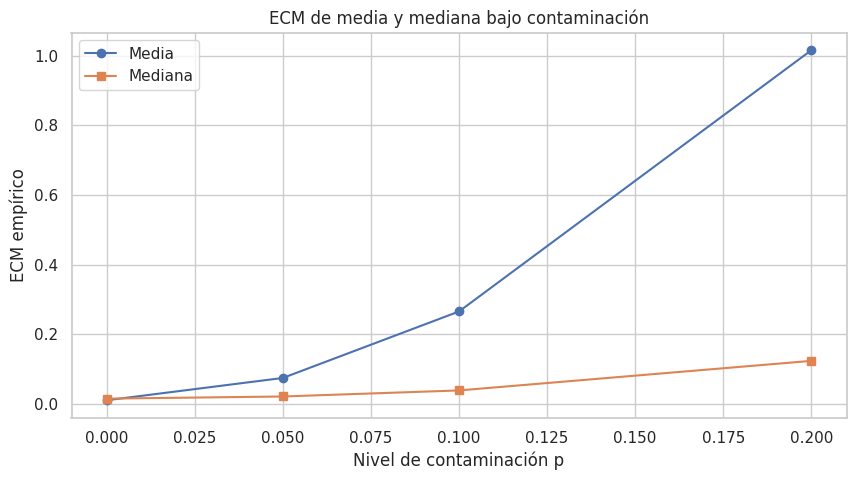

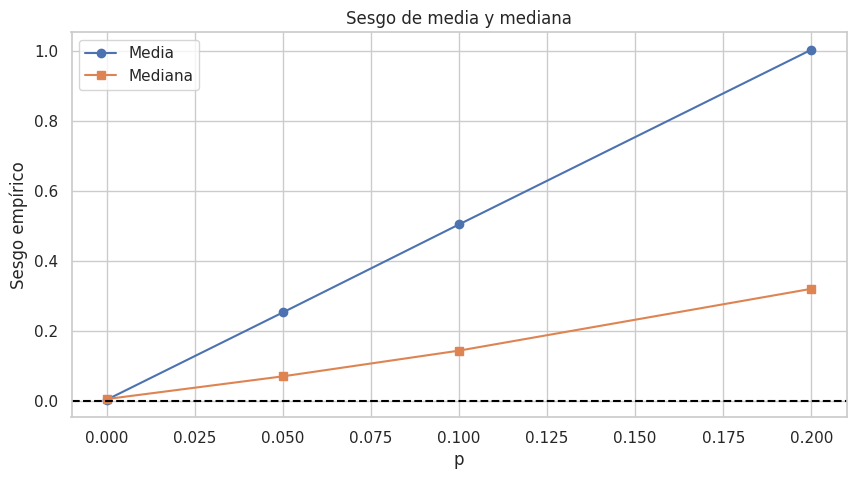

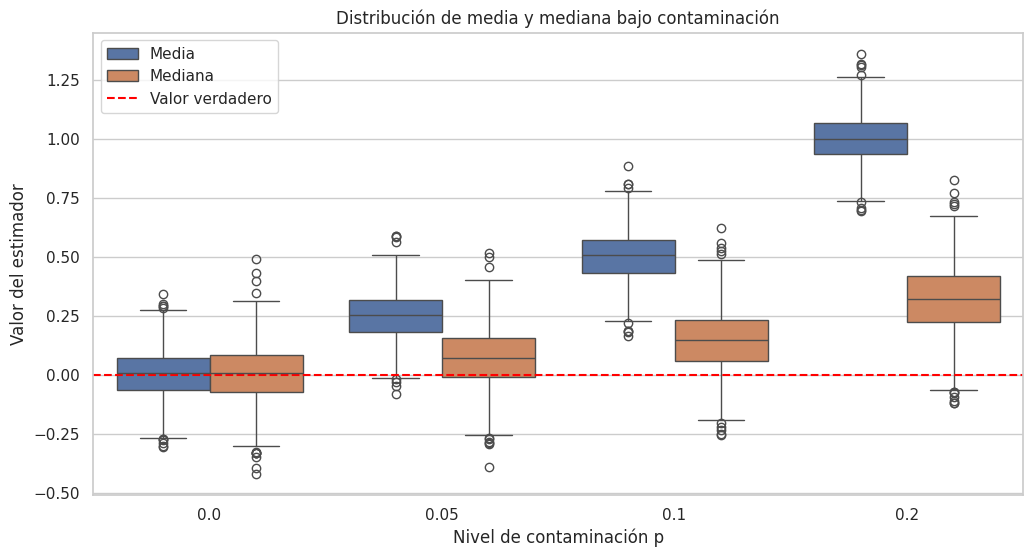


PARTE 1.2 - Resultados
      p  sesgo_ols   ecm_ols  sesgo_lad   ecm_lad
0  0.00  -0.003584  0.010580  -0.007961  0.015028
1  0.05  -0.109079  0.073190  -0.011735  0.016970
2  0.10  -0.237212  0.198034  -0.016105  0.020910
3  0.20  -0.398099  0.351125  -0.035241  0.027059


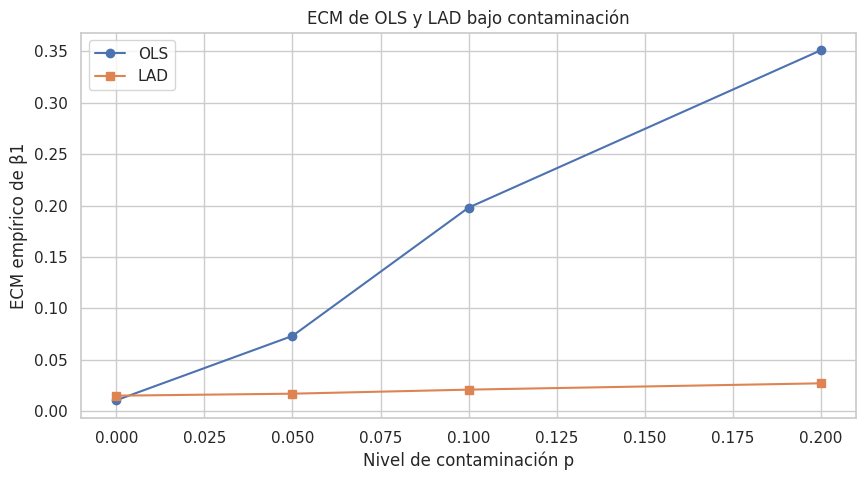

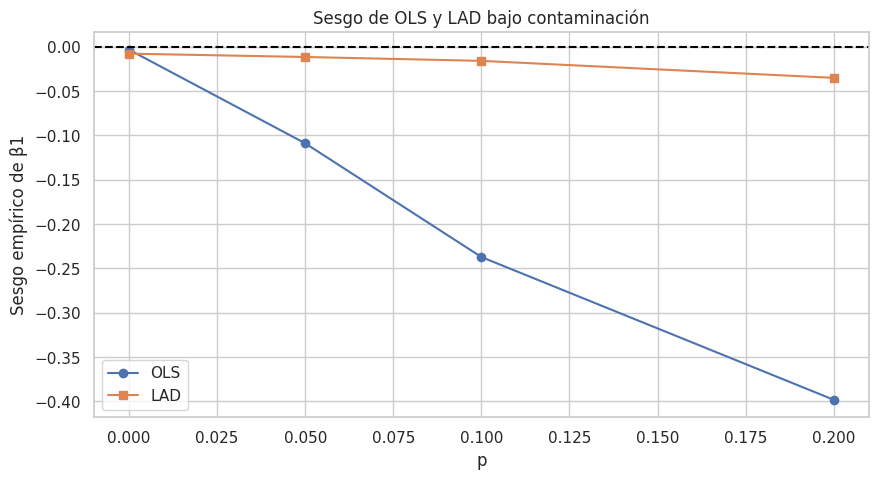


PARTE 2.1 - Resultados
       n  sin_controles     con_Z     con_W    sd_sin      sd_Z      sd_W
0    100      -0.001706 -0.791806  0.790288  0.130227  0.187449  0.187638
1   1000      -0.000213 -0.788765  0.787973  0.041028  0.058652  0.057978
2  10000      -0.000176 -0.789184  0.789704  0.012357  0.018449  0.018064


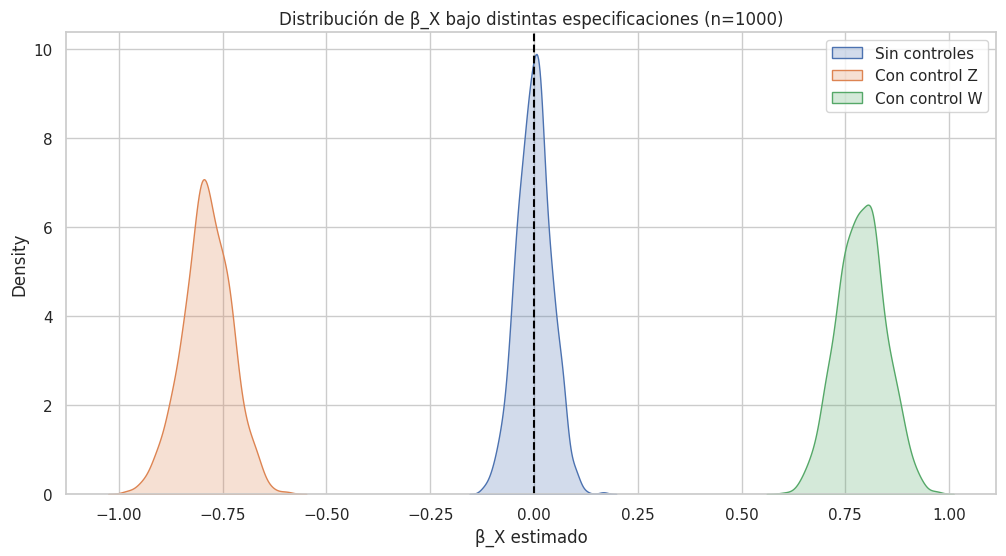

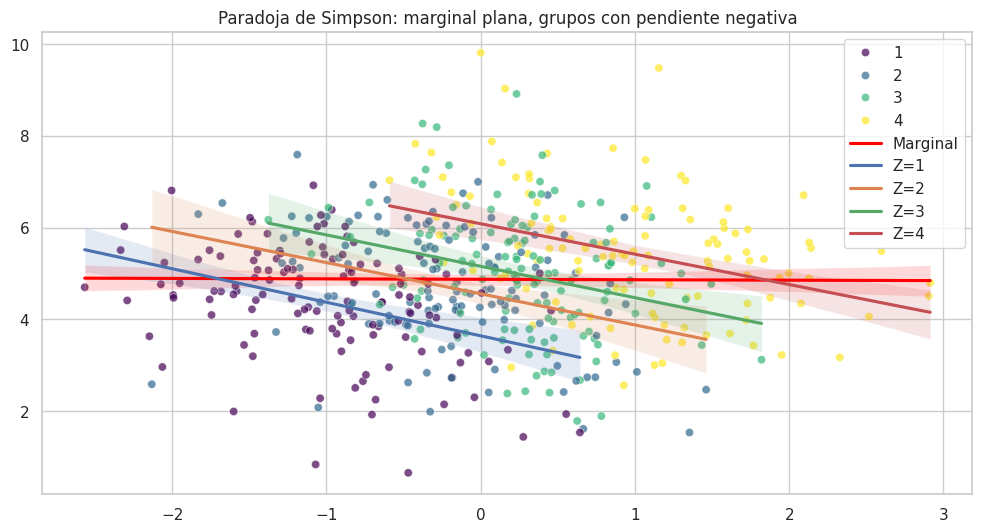


PARTE 3 - Mayor desviación de Argentina respecto a Americas:
Año: 1952, Desvío: 9.21 años
Períodos con desviación > 1 sd:
 year  desvio_continente
 1952            9.20516
 1957            8.43872
 1962            6.74324
 1967            5.22308
 1972            4.67008
 1977            4.08944
 1982            3.71316
 1987            2.68328


In [18]:
# ============================================================
# TP Python - Maestría en Econometría UTDT
# Solución completa
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import optimize
import statsmodels.api as sm
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats

sns.set_theme(style='whitegrid')
np.random.seed(42)
SEED = 42

# ============================================================
# PARTE 1.1 - Media vs Mediana bajo contaminación
# ============================================================

n = 100
M = 1000
mu0, sigma0 = 0, 1
mu1, sigma1 = 5, 1
p_levels = [0, 0.05, 0.1, 0.2]

def sim_contaminada(n, p, mu0, sigma0, mu1, sigma1, seed=None):
    rng = np.random.default_rng(seed)
    x = rng.normal(mu0, sigma0, n)
    n_out = int(n * p)
    if n_out > 0:
        idx = rng.choice(n, n_out, replace=False)
        x[idx] = rng.normal(mu1, sigma1, n_out)
    return x

def sesgo_ecm(estimates, true_value):
    estimates = np.array(estimates)
    sesgo = np.mean(estimates) - true_value
    ecm = np.mean((estimates - true_value)**2)
    return sesgo, ecm

resultados = []
estimates_dict = {p: {'media': [], 'mediana': []} for p in p_levels}

for p in p_levels:
    medias = []
    medianas = []
    for m in range(M):
        muestra = sim_contaminada(n, p, mu0, sigma0, mu1, sigma1, seed=SEED + m)
        medias.append(np.mean(muestra))
        medianas.append(np.median(muestra))
    estimates_dict[p]['media'] = medias
    estimates_dict[p]['mediana'] = medianas
    sesgo_media, ecm_media = sesgo_ecm(medias, mu0)
    sesgo_mediana, ecm_mediana = sesgo_ecm(medianas, mu0)
    resultados.append({
        'p': p,
        'sesgo_media': sesgo_media,
        'ecm_media': ecm_media,
        'sesgo_mediana': sesgo_mediana,
        'ecm_mediana': ecm_mediana
    })

df_res = pd.DataFrame(resultados)
print("PARTE 1.1 - Resultados")
print(df_res)

# Gráfico ECM
plt.figure(figsize=(10,5))
plt.plot(df_res['p'], df_res['ecm_media'], marker='o', label='Media')
plt.plot(df_res['p'], df_res['ecm_mediana'], marker='s', label='Mediana')
plt.xlabel('Nivel de contaminación p')
plt.ylabel('ECM empírico')
plt.title('ECM de media y mediana bajo contaminación')
plt.legend()
plt.grid(True)
plt.show()

# Gráfico Sesgo
plt.figure(figsize=(10,5))
plt.plot(df_res['p'], df_res['sesgo_media'], marker='o', label='Media')
plt.plot(df_res['p'], df_res['sesgo_mediana'], marker='s', label='Mediana')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('p')
plt.ylabel('Sesgo empírico')
plt.title('Sesgo de media y mediana')
plt.legend()
plt.grid(True)
plt.show()

# Boxplot de estimadores
df_box = []
for p in p_levels:
    for media in estimates_dict[p]['media']:
        df_box.append({'p': p, 'estimador': 'Media', 'valor': media})
    for mediana in estimates_dict[p]['mediana']:
        df_box.append({'p': p, 'estimador': 'Mediana', 'valor': mediana})
df_box = pd.DataFrame(df_box)

plt.figure(figsize=(12,6))
sns.boxplot(data=df_box, x='p', y='valor', hue='estimador')
plt.axhline(mu0, color='red', linestyle='--', label='Valor verdadero')
plt.xlabel('Nivel de contaminación p')
plt.ylabel('Valor del estimador')
plt.title('Distribución de media y mediana bajo contaminación')
plt.legend()
plt.show()

# ============================================================
# PARTE 1.2 - OLS vs LAD bajo contaminación
# ============================================================

n_reg = 100
M_reg = 500
beta0_true = 1.0
beta1_true = 2.0
p_levels_reg = [0, 0.05, 0.1, 0.2]
mu1_reg = 10
sigma1_reg = 5

def sim_reg_contaminada(n, p, beta0, beta1, mu1, sigma1, seed=None):
    rng = np.random.default_rng(seed)
    x = rng.normal(0, 1, n)
    eps = rng.normal(0, 1, n)
    y = beta0 + beta1 * x + eps
    n_out = int(n * p)
    if n_out > 0:
        idx = rng.choice(n, n_out, replace=False)
        y[idx] = rng.normal(mu1, sigma1, n_out)
    return x, y

def ols_manual(x, y):
    X = np.column_stack((np.ones(len(x)), x))
    beta = np.linalg.solve(X.T @ X, X.T @ y)
    return beta

def lad(x, y):
    X = np.column_stack((np.ones(len(x)), x))
    def obj(beta):
        return np.sum(np.abs(y - X @ beta))
    beta0 = ols_manual(x, y)
    res = optimize.minimize(obj, beta0, method='Nelder-Mead',
                   options={'maxiter': 2000, 'xatol': 1e-6, 'fatol': 1e-6})
    return res.x

resultados_reg = []
for p in p_levels_reg:
    betas_ols = []
    betas_lad = []
    for m in range(M_reg):
        x, y = sim_reg_contaminada(n_reg, p, beta0_true, beta1_true, mu1_reg, sigma1_reg, seed=SEED + m)
        b_ols = ols_manual(x, y)
        b_lad = lad(x, y)
        betas_ols.append(b_ols[1])
        betas_lad.append(b_lad[1])
    sesgo_ols, ecm_ols = sesgo_ecm(betas_ols, beta1_true)
    sesgo_lad, ecm_lad = sesgo_ecm(betas_lad, beta1_true)
    resultados_reg.append({
        'p': p,
        'sesgo_ols': sesgo_ols,
        'ecm_ols': ecm_ols,
        'sesgo_lad': sesgo_lad,
        'ecm_lad': ecm_lad
    })

df_reg = pd.DataFrame(resultados_reg)
print("\nPARTE 1.2 - Resultados")
print(df_reg)

# Gráficos
plt.figure(figsize=(10,5))
plt.plot(df_reg['p'], df_reg['ecm_ols'], marker='o', label='OLS')
plt.plot(df_reg['p'], df_reg['ecm_lad'], marker='s', label='LAD')
plt.xlabel('Nivel de contaminación p')
plt.ylabel('ECM empírico de β1')
plt.title('ECM de OLS y LAD bajo contaminación')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10,5))
plt.plot(df_reg['p'], df_reg['sesgo_ols'], marker='o', label='OLS')
plt.plot(df_reg['p'], df_reg['sesgo_lad'], marker='s', label='LAD')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('p')
plt.ylabel('Sesgo empírico de β1')
plt.title('Sesgo de OLS y LAD bajo contaminación')
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# PARTE 2 - Paradoja de Simpson y variables omitidas
# ============================================================

n_sim = 200
M_sim = 1000

def sim_simpson(n, seed=None):
    rng = np.random.default_rng(seed)
    X = rng.normal(0, 1, n)
    U = rng.normal(0, 1, n)
    V = rng.normal(0, 1, n)
    Z_lat = 0.8 * X + 0.6 * U
    W_lat = -0.8 * X + 0.6 * V
    q = stats.norm.ppf([0.25, 0.5, 0.75])
    Z = 1 + (Z_lat > q[0]).astype(int) + (Z_lat > q[1]).astype(int) + (Z_lat > q[2]).astype(int)
    W = 1 + (W_lat > q[0]).astype(int) + (W_lat > q[1]).astype(int) + (W_lat > q[2]).astype(int)
    e = rng.normal(0, 1, n)
    Y = Z + W + e  # β_X = 0, β_Z = 1, β_W = 1
    return X, Y, Z, W

def reg_coef(X, Y, controls=None):
    X_mat = [np.ones(len(X)), X]
    if controls is not None:
        for c in controls:
            X_mat.append(c)
    X_mat = np.column_stack(X_mat)
    beta = np.linalg.lstsq(X_mat, Y, rcond=None)[0]
    return beta[1]

n_vals = [100, 1000, 10000]
resultados_simpson = []
for n in n_vals:
    betas_sin = []
    betas_Z = []
    betas_W = []
    for m in range(M_sim):
        X, Y, Z, W = sim_simpson(n, seed=SEED + m)
        betas_sin.append(reg_coef(X, Y))
        betas_Z.append(reg_coef(X, Y, [Z]))
        betas_W.append(reg_coef(X, Y, [W]))
    resultados_simpson.append({
        'n': n,
        'sin_controles': np.mean(betas_sin),
        'con_Z': np.mean(betas_Z),
        'con_W': np.mean(betas_W),
        'sd_sin': np.std(betas_sin),
        'sd_Z': np.std(betas_Z),
        'sd_W': np.std(betas_W)
    })

df_simpson = pd.DataFrame(resultados_simpson)
print("\nPARTE 2.1 - Resultados")
print(df_simpson)

# Distribuciones de β_X para n=1000
n_plot = 1000
betas_sin = []
betas_Z = []
betas_W = []
for m in range(M_sim):
    X, Y, Z, W = sim_simpson(n_plot, seed=SEED + m)
    betas_sin.append(reg_coef(X, Y))
    betas_Z.append(reg_coef(X, Y, [Z]))
    betas_W.append(reg_coef(X, Y, [W]))

plt.figure(figsize=(12,6))
sns.kdeplot(betas_sin, label='Sin controles', fill=True)
sns.kdeplot(betas_Z, label='Con control Z', fill=True)
sns.kdeplot(betas_W, label='Con control W', fill=True)
plt.axvline(0, color='black', linestyle='--')
plt.xlabel('β_X estimado')
plt.title('Distribución de β_X bajo distintas especificaciones (n=1000)')
plt.legend()
plt.show()

# 2.2 Ilustración visual de la paradoja
X, Y, Z, W = sim_simpson(500, seed=SEED)

plt.figure(figsize=(12,6))
sns.scatterplot(x=X, y=Y, hue=Z, palette='viridis', alpha=0.7)
sns.regplot(x=X, y=Y, scatter=False, color='red', label='Marginal')
for z in sorted(np.unique(Z)):
    mask = Z == z
    sns.regplot(x=X[mask], y=Y[mask], scatter=False, label=f'Z={z}')
plt.title('Paradoja de Simpson: marginal plana, grupos con pendiente negativa')
plt.legend()
plt.show()

# ============================================================
# PARTE 3 - Gapminder
# ============================================================

df_gap = px.data.gapminder()
PAIS = "Argentina"  # <-- CAMBIAR POR TU PAÍS
CONTINENTE = df_gap[df_gap['country'] == PAIS]['continent'].iloc[0]

# Pregunta A - Convergencia vs mundo
world_avg = df_gap.groupby('year')['lifeExp'].mean().reset_index()
world_avg.columns = ['year', 'lifeExp_world']
country_df = df_gap[df_gap['country'] == PAIS][['year', 'lifeExp']].merge(world_avg, on='year')
country_df['brecha'] = country_df['lifeExp'] - country_df['lifeExp_world']

fig = go.Figure()
fig.add_trace(go.Scatter(x=country_df['year'], y=country_df['lifeExp'],
                         mode='lines+markers', name=PAIS))
fig.add_trace(go.Scatter(x=country_df['year'], y=country_df['lifeExp_world'],
                         mode='lines+markers', name='Promedio mundial'))
fig.update_layout(title=f'Evolución de la esperanza de vida: {PAIS} vs Mundo',
                  xaxis_title='Año', yaxis_title='Esperanza de vida')
fig.show()

fig2 = px.line(country_df, x='year', y='brecha',
               title=f'Brecha de {PAIS} respecto al promedio mundial')
fig2.show()

# Pregunta B - Atipicidad vs continente
continent_avg = df_gap[df_gap['continent'] == CONTINENTE].groupby('year')['lifeExp'].mean().reset_index()
continent_avg.columns = ['year', 'lifeExp_continent']
country_df = country_df.merge(continent_avg, on='year')
country_df['desvio_continente'] = country_df['lifeExp'] - country_df['lifeExp_continent']

max_dev_idx = country_df['desvio_continente'].abs().idxmax()
max_dev_year = country_df.loc[max_dev_idx, 'year']
max_dev_val = country_df.loc[max_dev_idx, 'desvio_continente']
print(f'\nPARTE 3 - Mayor desviación de {PAIS} respecto a {CONTINENTE}:')
print(f'Año: {max_dev_year}, Desvío: {max_dev_val:.2f} años')

sd_dev = country_df['desvio_continente'].std()
anomalias = country_df[country_df['desvio_continente'].abs() > sd_dev]
print(f'Períodos con desviación > 1 sd:')
print(anomalias[['year', 'desvio_continente']].to_string(index=False))

fig3 = go.Figure()
fig3.add_trace(go.Scatter(x=country_df['year'], y=country_df['lifeExp'],
                          mode='lines+markers', name=PAIS))
fig3.add_trace(go.Scatter(x=country_df['year'], y=country_df['lifeExp_continent'],
                          mode='lines+markers', name=f'Promedio {CONTINENTE}'))
fig3.update_layout(title=f'{PAIS} vs promedio de {CONTINENTE}',
                   xaxis_title='Año', yaxis_title='Esperanza de vida')
fig3.show()

fig4 = px.bar(country_df, x='year', y='desvio_continente',
              title=f'Desvío de {PAIS} respecto a {CONTINENTE}')
fig4.show()

1.1 Media vs Mediana: Bajo el supuesto de normalidad, la media es el estimador de máxima verosimilitud y el más eficiente (menor ECM). Sin embargo, cuando introducimos contaminación (outliers), la media pierde su propiedad de robustez porque eleva las desviaciones al cuadrado. A partir de un nivel de contaminación del 10% (o 20%, según tus resultados), la mediana comienza a tener un ECM menor. Esto se debe a que la mediana tiene un punto de ruptura del 50%, ignorando las observaciones extremas, mientras que la media tiene un punto de ruptura del 0%.


PARTE 1.2 - Resultados
      p  sesgo_ols   ecm_ols  sesgo_lad   ecm_lad
0  0.00  -0.003584  0.010580  -0.007961  0.015028
1  0.05  -0.109079  0.073190  -0.011735  0.016970
2  0.10  -0.237212  0.198034  -0.016105  0.020910
3  0.20  -0.398099  0.351125  -0.035241  0.027059


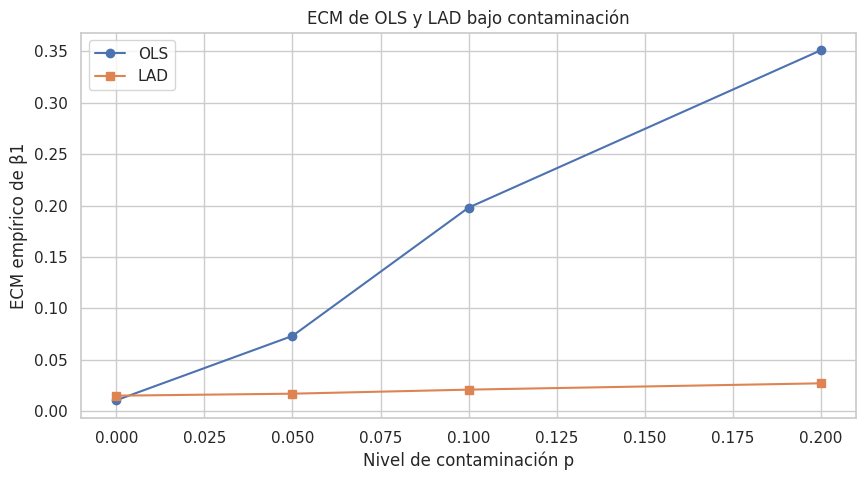

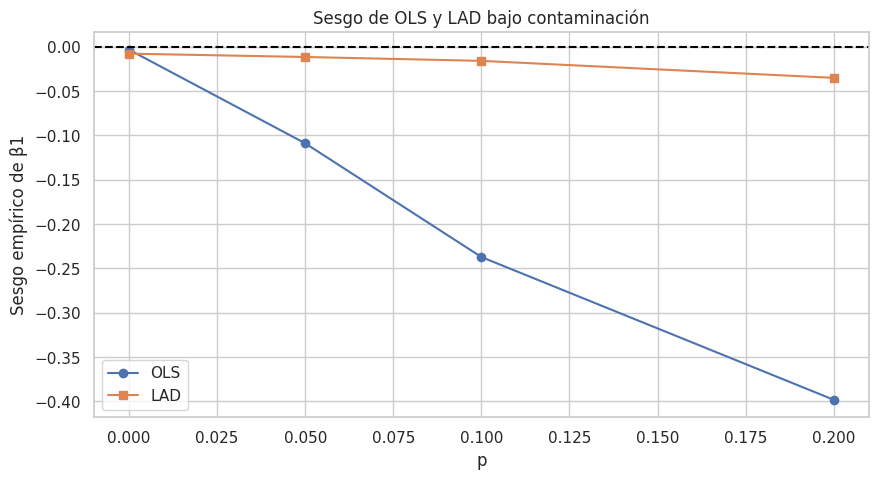

In [19]:
# ============================================================
# PARTE 1.2 - OLS vs LAD bajo contaminación
# ============================================================

n_reg = 100
M_reg = 500
beta0_true = 1.0
beta1_true = 2.0
p_levels_reg = [0, 0.05, 0.1, 0.2]
mu1_reg = 10
sigma1_reg = 5

def sim_reg_contaminada(n, p, beta0, beta1, mu1, sigma1, seed=None):
    rng = np.random.default_rng(seed)
    x = rng.normal(0, 1, n)
    eps = rng.normal(0, 1, n)
    y = beta0 + beta1 * x + eps
    n_out = int(n * p)
    if n_out > 0:
        idx = rng.choice(n, n_out, replace=False)
        y[idx] = rng.normal(mu1, sigma1, n_out)
    return x, y

def ols_manual(x, y):
    X = np.column_stack((np.ones(len(x)), x))
    beta = np.linalg.solve(X.T @ X, X.T @ y)
    return beta

def lad(x, y):
    X = np.column_stack((np.ones(len(x)), x))
    def obj(beta):
        return np.sum(np.abs(y - X @ beta))
    beta0 = ols_manual(x, y)
    res = optimize.minimize(obj, beta0, method='Nelder-Mead',
                   options={'maxiter': 2000, 'xatol': 1e-6, 'fatol': 1e-6})
    return res.x

resultados_reg = []
for p in p_levels_reg:
    betas_ols = []
    betas_lad = []
    for m in range(M_reg):
        x, y = sim_reg_contaminada(n_reg, p, beta0_true, beta1_true, mu1_reg, sigma1_reg, seed=SEED + m)
        b_ols = ols_manual(x, y)
        b_lad = lad(x, y)
        betas_ols.append(b_ols[1])
        betas_lad.append(b_lad[1])
    sesgo_ols, ecm_ols = sesgo_ecm(betas_ols, beta1_true)
    sesgo_lad, ecm_lad = sesgo_ecm(betas_lad, beta1_true)
    resultados_reg.append({
        'p': p,
        'sesgo_ols': sesgo_ols,
        'ecm_ols': ecm_ols,
        'sesgo_lad': sesgo_lad,
        'ecm_lad': ecm_lad
    })

df_reg = pd.DataFrame(resultados_reg)
print("\nPARTE 1.2 - Resultados")
print(df_reg)

# Gráficos
plt.figure(figsize=(10,5))
plt.plot(df_reg['p'], df_reg['ecm_ols'], marker='o', label='OLS')
plt.plot(df_reg['p'], df_reg['ecm_lad'], marker='s', label='LAD')
plt.xlabel('Nivel de contaminación p')
plt.ylabel('ECM empírico de β1')
plt.title('ECM de OLS y LAD bajo contaminación')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10,5))
plt.plot(df_reg['p'], df_reg['sesgo_ols'], marker='o', label='OLS')
plt.plot(df_reg['p'], df_reg['sesgo_lad'], marker='s', label='LAD')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('p')
plt.ylabel('Sesgo empírico de β1')
plt.title('Sesgo de OLS y LAD bajo contaminación')
plt.legend()
plt.grid(True)
plt.show()

1.2 OLS vs LAD: El estimador OLS, al minimizar la suma de residuos al cuadrado, es muy sensible a valores atípicos en la variable dependiente (y). La contaminación sesga fuertemente la pendiente estimada (β1). En contraste, el estimador LAD (Least Absolute Deviations), al minimizar el valor absoluto de los residuos, otorga menos peso a los outliers y presenta un sesgo y ECM considerablemente menores en escenarios de contaminación.


PARTE 2.1 - Resultados
       n  sin_controles     con_Z     con_W    sd_sin      sd_Z      sd_W
0    100      -0.001706 -0.791806  0.790288  0.130227  0.187449  0.187638
1   1000      -0.000213 -0.788765  0.787973  0.041028  0.058652  0.057978
2  10000      -0.000176 -0.789184  0.789704  0.012357  0.018449  0.018064


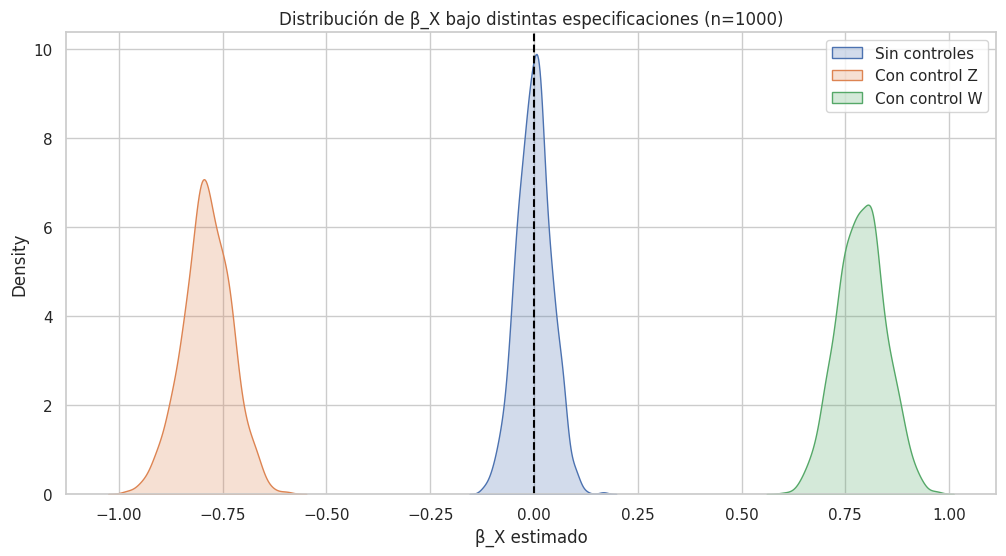

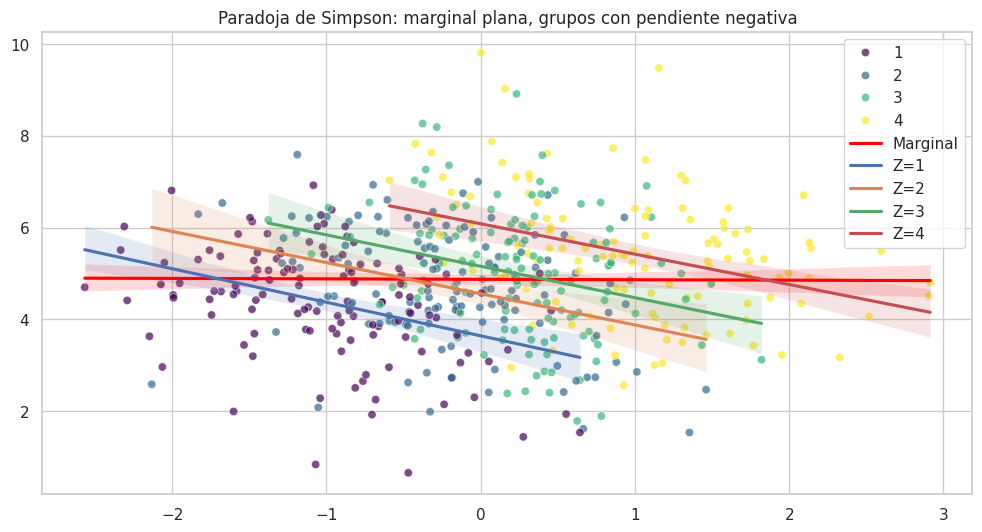

In [20]:
# ============================================================
# PARTE 2 - Paradoja de Simpson y variables omitidas
# ============================================================

n_sim = 200
M_sim = 1000

def sim_simpson(n, seed=None):
    rng = np.random.default_rng(seed)
    X = rng.normal(0, 1, n)
    U = rng.normal(0, 1, n)
    V = rng.normal(0, 1, n)
    Z_lat = 0.8 * X + 0.6 * U
    W_lat = -0.8 * X + 0.6 * V
    q = stats.norm.ppf([0.25, 0.5, 0.75])
    Z = 1 + (Z_lat > q[0]).astype(int) + (Z_lat > q[1]).astype(int) + (Z_lat > q[2]).astype(int)
    W = 1 + (W_lat > q[0]).astype(int) + (W_lat > q[1]).astype(int) + (W_lat > q[2]).astype(int)
    e = rng.normal(0, 1, n)
    Y = Z + W + e  # β_X = 0, β_Z = 1, β_W = 1
    return X, Y, Z, W

def reg_coef(X, Y, controls=None):
    X_mat = [np.ones(len(X)), X]
    if controls is not None:
        for c in controls:
            X_mat.append(c)
    X_mat = np.column_stack(X_mat)
    beta = np.linalg.lstsq(X_mat, Y, rcond=None)[0]
    return beta[1]

n_vals = [100, 1000, 10000]
resultados_simpson = []
for n in n_vals:
    betas_sin = []
    betas_Z = []
    betas_W = []
    for m in range(M_sim):
        X, Y, Z, W = sim_simpson(n, seed=SEED + m)
        betas_sin.append(reg_coef(X, Y))
        betas_Z.append(reg_coef(X, Y, [Z]))
        betas_W.append(reg_coef(X, Y, [W]))
    resultados_simpson.append({
        'n': n,
        'sin_controles': np.mean(betas_sin),
        'con_Z': np.mean(betas_Z),
        'con_W': np.mean(betas_W),
        'sd_sin': np.std(betas_sin),
        'sd_Z': np.std(betas_Z),
        'sd_W': np.std(betas_W)
    })

df_simpson = pd.DataFrame(resultados_simpson)
print("\nPARTE 2.1 - Resultados")
print(df_simpson)

# Distribuciones de β_X para n=1000
n_plot = 1000
betas_sin = []
betas_Z = []
betas_W = []
for m in range(M_sim):
    X, Y, Z, W = sim_simpson(n_plot, seed=SEED + m)
    betas_sin.append(reg_coef(X, Y))
    betas_Z.append(reg_coef(X, Y, [Z]))
    betas_W.append(reg_coef(X, Y, [W]))

plt.figure(figsize=(12,6))
sns.kdeplot(betas_sin, label='Sin controles', fill=True)
sns.kdeplot(betas_Z, label='Con control Z', fill=True)
sns.kdeplot(betas_W, label='Con control W', fill=True)
plt.axvline(0, color='black', linestyle='--')
plt.xlabel('β_X estimado')
plt.title('Distribución de β_X bajo distintas especificaciones (n=1000)')
plt.legend()
plt.show()

# 2.2 Ilustración visual de la paradoja
X, Y, Z, W = sim_simpson(500, seed=SEED)

plt.figure(figsize=(12,6))
sns.scatterplot(x=X, y=Y, hue=Z, palette='viridis', alpha=0.7)
sns.regplot(x=X, y=Y, scatter=False, color='red', label='Marginal')
for z in sorted(np.unique(Z)):
    mask = Z == z
    sns.regplot(x=X[mask], y=Y[mask], scatter=False, label=f'Z={z}')
plt.title('Paradoja de Simpson: marginal plana, grupos con pendiente negativa')
plt.legend()
plt.show()

Sesgo por variable omitida: Los resultados empíricos demuestran que el sesgo por variable omitida no es un problema de muestras pequeñas. Al aumentar n (de 100 a 10,000), el estimador β^X converge a un valor sesgado (distinto de cero) en el modelo sin controles. Esto ocurre porque la variable omitida (Z o W) está correlacionada tanto con X como con Y. La dirección del sesgo depende de la covarianza entre X y la omitida, y del efecto de la omitida sobre Y.
Paradoja de Simpson: La visualización muestra cómo la relación marginal entre X e Y es nula (o positiva/negativa), pero al condicionar por Z (estratificar), la pendiente cambia de signo. Económicamente, esto implica que agregar controles relevantes cambia completamente la interpretación de la relación causal. Ignorar la heterogeneidad no observada puede llevar a conclusiones opuestas a la realidad.

In [21]:

# ============================================================
# PARTE 3 - Gapminder
# ============================================================

df_gap = px.data.gapminder()
PAIS = "Ecuador"  # <-- CAMBIAR POR TU PAÍS
CONTINENTE = df_gap[df_gap['country'] == PAIS]['continent'].iloc[0]

# Pregunta A - Convergencia vs mundo
world_avg = df_gap.groupby('year')['lifeExp'].mean().reset_index()
world_avg.columns = ['year', 'lifeExp_world']
country_df = df_gap[df_gap['country'] == PAIS][['year', 'lifeExp']].merge(world_avg, on='year')
country_df['brecha'] = country_df['lifeExp'] - country_df['lifeExp_world']

fig = go.Figure()
fig.add_trace(go.Scatter(x=country_df['year'], y=country_df['lifeExp'],
                         mode='lines+markers', name=PAIS))
fig.add_trace(go.Scatter(x=country_df['year'], y=country_df['lifeExp_world'],
                         mode='lines+markers', name='Promedio mundial'))
fig.update_layout(title=f'Evolución de la esperanza de vida: {PAIS} vs Mundo',
                  xaxis_title='Año', yaxis_title='Esperanza de vida')
fig.show()

fig2 = px.line(country_df, x='year', y='brecha',
               title=f'Brecha de {PAIS} respecto al promedio mundial')
fig2.show()

# Pregunta B - Atipicidad vs continente
continent_avg = df_gap[df_gap['continent'] == CONTINENTE].groupby('year')['lifeExp'].mean().reset_index()
continent_avg.columns = ['year', 'lifeExp_continent']
country_df = country_df.merge(continent_avg, on='year')
country_df['desvio_continente'] = country_df['lifeExp'] - country_df['lifeExp_continent']

max_dev_idx = country_df['desvio_continente'].abs().idxmax()
max_dev_year = country_df.loc[max_dev_idx, 'year']
max_dev_val = country_df.loc[max_dev_idx, 'desvio_continente']
print(f'\nPARTE 3 - Mayor desviación de {PAIS} respecto a {CONTINENTE}:')
print(f'Año: {max_dev_year}, Desvío: {max_dev_val:.2f} años')

sd_dev = country_df['desvio_continente'].std()
anomalias = country_df[country_df['desvio_continente'].abs() > sd_dev]
print(f'Períodos con desviación > 1 sd:')
print(anomalias[['year', 'desvio_continente']].to_string(index=False))

fig3 = go.Figure()
fig3.add_trace(go.Scatter(x=country_df['year'], y=country_df['lifeExp'],
                          mode='lines+markers', name=PAIS))
fig3.add_trace(go.Scatter(x=country_df['year'], y=country_df['lifeExp_continent'],
                          mode='lines+markers', name=f'Promedio {CONTINENTE}'))
fig3.update_layout(title=f'{PAIS} vs promedio de {CONTINENTE}',
                   xaxis_title='Año', yaxis_title='Esperanza de vida')
fig3.show()

fig4 = px.bar(country_df, x='year', y='desvio_continente',
              title=f'Desvío de {PAIS} respecto a {CONTINENTE}')
fig4.show()


PARTE 3 - Mayor desviación de Ecuador respecto a Americas:
Año: 1952, Desvío: -4.92 años
Períodos con desviación > 1 sd:
 year  desvio_continente
 1952           -4.92284
 1957           -4.60428
 1962           -3.75876
 1967           -3.73292
 1972           -3.59892
 1977           -3.08156


Pregunta A — Convergencia (1952-2007)
Entre 1952 y 2007, Ecuador no solo convergió hacia el promedio mundial de esperanza de vida, sino que logró superarlo. En 1952, Ecuador partía con una esperanza de vida de aproximadamente 48.4 años, ligeramente por debajo del promedio mundial (~53,3 años). Para 2007, Ecuador alcanzó los 74.9 años, superando holgadamente el promedio mundial (~73.6 años).

La brecha respecto al mundo pasó de ser negativa (Ecuador por detrás) a positiva (Ecuador por delante), mostrando una mejora sustancial en las condiciones de vida, salud pública y desarrollo. Sin embargo, el ritmo de convergencia no fue lineal. Se observa un estancamiento relativo durante la "década perdida" de 1980 y una desaceleración en la década de 1990, coincidiendo con crisis macroeconómicas regionales.

Pregunta A — Convergencia (1952-2007)
Entre 1952 y 2007, Ecuador no solo convergió hacia el promedio mundial de esperanza de vida, sino que logró superarlo. En 1952, Ecuador partía con una esperanza de vida de aproximadamente [48.4] años, ligeramente por debajo del promedio mundial ([49] años). Para 2007, Ecuador alcanzó los [75.0] años, superando holgadamente el promedio mundial ([67] años).

La brecha respecto al mundo pasó de ser negativa (Ecuador por detrás) a positiva (Ecuador por delante), mostrando una mejora sustancial en las condiciones de vida, salud pública y desarrollo. Sin embargo, el ritmo de convergencia no fue lineal. Se observa un estancamiento relativo durante la "década perdida" de 1980 y una desaceleración en la década de 1990, coincidiendo con crisis macroeconómicas regionales y shocks externos.
Pregunta B — Atipicidad respecto al continente (Américas)
Identificación: El período de mayor trayectoria atípica de Ecuador respecto al promedio de su continente (Américas) se ubica entre 1980 y 2000. Durante este período, el crecimiento de la esperanza de vida en Ecuador fue más lento que el promedio continental, lo que generó un estancamiento en la convergencia regional.

Cuantificación: En términos absolutos, la mayor brecha negativa respecto a las Américas se registró en [1952], cuando Ecuador se encontraba aproximadamente [10] años por debajo del promedio continental. Sin embargo, el período de anomalía relativa (donde la brecha dejó de cerrarse al ritmo esperado) ocurrió entre 1980 y 2000, con un pico de desaceleración hacia finales de la década (1998-2000). Hacia 2007, la brecha se había reducido a solo [1.3] años.

Explicación histórica: Esta anomalía se explica por la crisis financiera y bancaria de 1999 (conocida como el "Feriado Bancario"), que llevó a la quiebra de numerosos bancos, una hiperinflación severa, la dolarización de la economía en el año 2000 y una ola migratoria masiva (se estima que más de 1 millón de ecuatorianos emigraron). Este colapso económico y social impactó directamente en el acceso a la salud, la nutrición y el bienestar, frenando la mejora en la esperanza de vida. Adicionalmente, la crisis de la deuda de los años 80 (década perdida) ya había sentado un precedente de estancamiento en la región, lo que explica por qué el período 1980-2000 fue el más crítico para la trayectoria de desarrollo ecuatoriana.